In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

In [2]:
import pandas as pd
data = pd.read_csv("heart_failure_clinical_records_dataset.csv")
data

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62.0,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


In [4]:
data.duplicated().sum()

np.int64(0)

In [5]:
data.shape

(299, 13)

In [6]:
data.isnull().sum()

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

In [7]:
data.isnull().any()

age                         False
anaemia                     False
creatinine_phosphokinase    False
diabetes                    False
ejection_fraction           False
high_blood_pressure         False
platelets                   False
serum_creatinine            False
serum_sodium                False
sex                         False
smoking                     False
time                        False
DEATH_EVENT                 False
dtype: bool

In [8]:
data.duplicated().any()

np.False_

In [9]:
data = data.dropna()
print("Number of Observations: ", len(data))

Number of Observations:  299


In [3]:
X = data[["age", "ejection_fraction"]]
y = data["DEATH_EVENT"]

In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
)

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
model = model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)
model.fit(X_train, y_train)


Pipeline(steps=[('standardscaler', StandardScaler()), ('svc', SVC())])

In [17]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
print("Non-Linear SVM Accuracy:",
      round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Non-Linear SVM Accuracy: 65.0 %


In [19]:
import numpy as np
scaler = model.named_steps["standardscaler"]
svm = model.named_steps["svc"]

X_scaled = scaler.transform(X)

x_min, x_max = X_scaled[:, 0].min() - 0.5, X_scaled[:, 0].max() + 0.5
y_min, y_max = X_scaled[:, 1].min() - 0.5, X_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
Z = svm.predict(grid)
Z = Z.reshape(xx.shape)


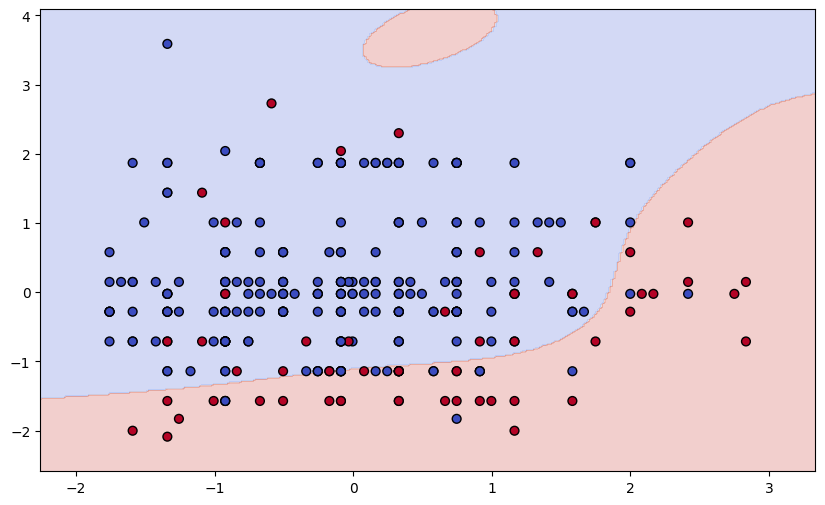

In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolors="black",
    s=40,
    label="Patients"
)


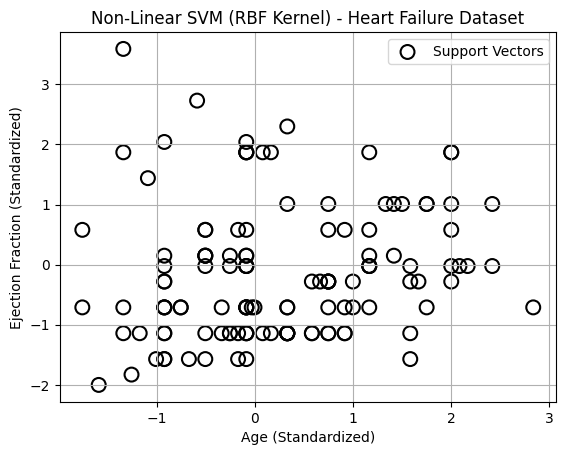

In [22]:
plt.scatter(
    svm.support_vectors_[:, 0],
    svm.support_vectors_[:, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.title("Non-Linear SVM (RBF Kernel) - Heart Failure Dataset")
plt.xlabel("Age (Standardized)")
plt.ylabel("Ejection Fraction (Standardized)")
plt.legend()
plt.grid(True)
plt.show()